# Student Mental Health Risk Analysis

### Term Project: Term Project Milestone 1: Data Selection and EDA

Data source:
A STATISTICAL RESEARCH ON THE EFFECTS OF MENTAL HEALTH ON STUDENTS’ CGPA dataset - https://www.kaggle.com/datasets/shariful07/student-mental-health
This Data set was collected by a survey conducted by Google forms from University student in order to examine their current academic situation and mental health.
All the data was based on Malaysia and collected from Iium (International Islamic University Malaysia).


>>  
Students’ mental health is very important for their academic success. If they do not maintain good mental health during their studies, they may struggle, fall behind, or even fail to complete their degree. This has become a growing concern worldwide because poor mental health can affect students’ long-term well-being and future careers.The purpose of this project is to analyze mental health risk among university students using survey data.
>>
>> Business Problem:- 
Can demographic and academic factors affect students’ mental health?
The goal is to help educational institutions identify at-risk students and provide support at the right time.




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    StratifiedKFold
)


from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

In [2]:
#Load data

df = pd.read_csv("Student Mental health.csv")

df.head()


,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


In [3]:
df.shape

(101, 11)

In [4]:
df.columns

Index(['Timestamp', 'Choose your gender', 'Age', 'What is your course?',
       'Your current year of Study', 'What is your CGPA?', 'Marital status',
       'Do you have Depression?', 'Do you have Anxiety?',
       'Do you have Panic attack?',
       'Did you seek any specialist for a treatment?'],
      dtype='object')

### EDA

In [5]:
df = df.copy()
df.columns = [c.strip() for c in df.columns]
print("Columns found:\n", df.columns.tolist())

Columns found:
 ['Timestamp', 'Choose your gender', 'Age', 'What is your course?', 'Your current year of Study', 'What is your CGPA?', 'Marital status', 'Do you have Depression?', 'Do you have Anxiety?', 'Do you have Panic attack?', 'Did you seek any specialist for a treatment?']


In [6]:
# Rename long survey columns to short analytics-friendly names
rename_map = {
    'Timestamp': 'timestamp',
    'Choose your gender': 'gender',
    'Age': 'age',
    'What is your course?': 'course',
    'Your current year of Study': 'study_year',
    'What is your CGPA?': 'cgpa_raw',
    'Marital status': 'marital_status',
    'Do you have Depression?': 'depression',
    'Do you have Anxiety?': 'anxiety',
    'Do you have Panic attack?': 'panic_attack',
    'Did you seek any specialist for a treatment?': 'sought_treatment'
}
df = df.rename(columns=rename_map)

In [7]:
print("Columns found:\n", df.columns.tolist())

Columns found:
 ['timestamp', 'gender', 'age', 'course', 'study_year', 'cgpa_raw', 'marital_status', 'depression', 'anxiety', 'panic_attack', 'sought_treatment']


In [8]:
df.head()

,timestamp,gender,age,course,study_year,cgpa_raw,marital_status,depression,anxiety,panic_attack,sought_treatment
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


In [9]:
# Standardize text columns
cat_cols = [
    'gender', 'course', 'study_year',
    'marital_status', 'depression',
    'anxiety', 'panic_attack', 'sought_treatment'
]

for c in cat_cols:
    df[c] = df[c].astype(str).str.strip().str.lower()

# Fix study_year consistency
df['study_year'] = df['study_year'].str.replace('year ', 'year_', regex=False)


In [10]:
#Convert yes/No to binary

binary_map = {'yes': 1, 'no': 0}

binary_cols = ['depression', 'anxiety', 'panic_attack', 'sought_treatment','marital_status']
for c in binary_cols:
    df[c] = df[c].map(binary_map)


In [11]:
df.head()

,timestamp,gender,age,course,study_year,cgpa_raw,marital_status,depression,anxiety,panic_attack,sought_treatment
0,8/7/2020 12:02,female,18.0,engineering,year_1,3.00 - 3.49,0,1,0,1,0
1,8/7/2020 12:04,male,21.0,islamic education,year_2,3.00 - 3.49,0,0,1,0,0
2,8/7/2020 12:05,male,19.0,bit,year_1,3.00 - 3.49,0,1,1,1,0
3,8/7/2020 12:06,female,22.0,laws,year_3,3.00 - 3.49,1,1,0,0,0
4,8/7/2020 12:13,male,23.0,mathemathics,year_4,3.00 - 3.49,0,0,0,0,0


In [12]:
#Convert CGPA range to numeric
def cgpa_midpoint(x):
    if pd.isna(x):
        return None
    lo, hi = x.split('-')
    return (float(lo.strip()) + float(hi.strip())) / 2

df['cgpa'] = df['cgpa_raw'].apply(cgpa_midpoint)

df.head()

,timestamp,gender,age,course,study_year,cgpa_raw,marital_status,depression,anxiety,panic_attack,sought_treatment,cgpa
0,8/7/2020 12:02,female,18.0,engineering,year_1,3.00 - 3.49,0,1,0,1,0,3.245
1,8/7/2020 12:04,male,21.0,islamic education,year_2,3.00 - 3.49,0,0,1,0,0,3.245
2,8/7/2020 12:05,male,19.0,bit,year_1,3.00 - 3.49,0,1,1,1,0,3.245
3,8/7/2020 12:06,female,22.0,laws,year_3,3.00 - 3.49,1,1,0,0,0,3.245
4,8/7/2020 12:13,male,23.0,mathemathics,year_4,3.00 - 3.49,0,0,0,0,0,3.245


In [13]:
df.isna().sum()

timestamp           0
gender              0
age                 1
course              0
study_year          0
cgpa_raw            0
marital_status      0
depression          0
anxiety             0
panic_attack        0
sought_treatment    0
cgpa                0
dtype: int64

In [14]:
#Fill in with median student age
df['age'] = df['age'].fillna(df['age'].median())


### Graphical Analysis 1: Overall Mental Health Among Students
visualization helps identify mental health rates among students

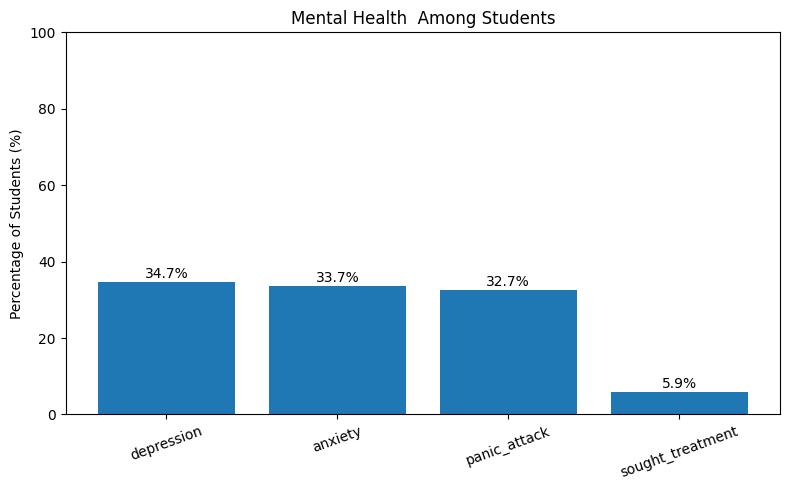

In [15]:
#Overall mental health

# Calculate percentages
kpi = df[['depression', 'anxiety', 'panic_attack', 'sought_treatment']].mean() * 100

# Plot
plt.figure(figsize=(8, 5))
plt.bar(kpi.index, kpi.values)

plt.ylabel('Percentage of Students (%)')
plt.title('Mental Health  Among Students')
plt.ylim(0, 100)

# Add value labels on bars
for i, v in enumerate(kpi.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


>> 34.7% of students have depression, 33.7% have anxiety and 32.7% have panic attack. ALso, only 5.9% seek treatment

### Graphical Ananlysis 2: Mental health  by CGPA Range

In [16]:
df_eda = df.dropna(subset=['cgpa']).copy()

df_eda['cgpa_range'] = pd.cut(
    df_eda['cgpa'],
    bins=[0, 2.99, 3.49, 4.01],
    labels=['< 3.00', '3.00 – 3.49', '3.50 – 4.00']
)


In [17]:
cgpa_mental = (
    df_eda
    .groupby('cgpa_range')[['depression', 'anxiety', 'panic_attack']]
    .mean() * 100
)

cgpa_mental


,depression,anxiety,panic_attack
cgpa_range,,,
< 3.00,30.000000,10.000000,50.000000
3.00 – 3.49,44.186047,34.883721,20.930233
3.50 – 4.00,27.083333,37.500000,39.583333


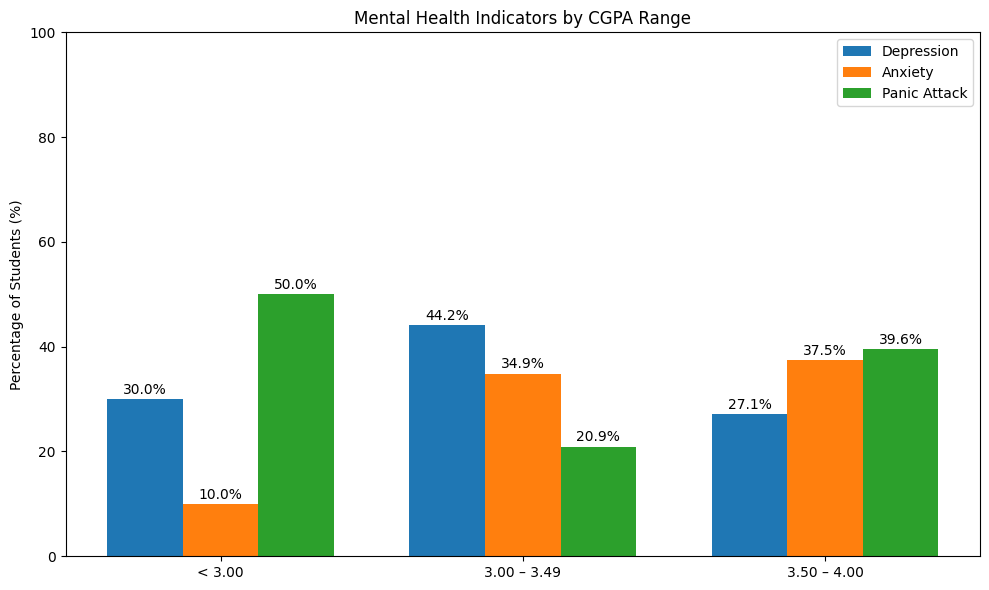

In [18]:
#Plot batchart

x = np.arange(len(cgpa_mental.index))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(x - width, cgpa_mental['depression'], width, label='Depression')
plt.bar(x,         cgpa_mental['anxiety'], width, label='Anxiety')
plt.bar(x + width, cgpa_mental['panic_attack'], width, label='Panic Attack')

plt.xticks(x, cgpa_mental.index)
plt.ylabel('Percentage of Students (%)')
plt.title('Mental Health Indicators by CGPA Range')
plt.ylim(0,100)
plt.legend()

# Value labels
for i in range(len(x)):
    plt.text(x[i] - width, cgpa_mental['depression'][i] + 1,
             f"{cgpa_mental['depression'][i]:.1f}%", ha='center')
    plt.text(x[i], cgpa_mental['anxiety'][i] + 1,
             f"{cgpa_mental['anxiety'][i]:.1f}%", ha='center')
    plt.text(x[i] + width, cgpa_mental['panic_attack'][i] + 1,
             f"{cgpa_mental['panic_attack'][i]:.1f}%", ha='center')

plt.tight_layout()
plt.show()


>> Students with CGPA less than 3 have very high panic attach (50%).Students in the CGPA range of 3 to 3.49 have more depression

### Graphical Analysis 3: Mental Health by Gender

In [19]:
#Calculate mental-health rates by gender
gender_mental = (
    df_eda
    .groupby('gender')[['depression', 'anxiety', 'panic_attack']]
    .mean()
    .mul(100)
    .sort_values(by='depression', ascending=False)
)

gender_mental


,depression,anxiety,panic_attack
gender,,,
female,38.666667,32.000000,33.333333
male,23.076923,38.461538,30.769231


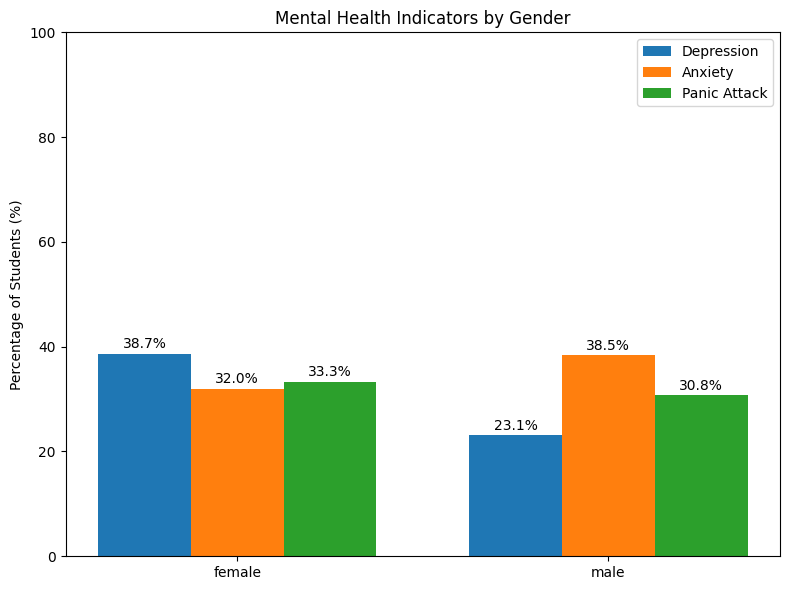

In [20]:
#Plot


x = np.arange(len(gender_mental.index))
width = 0.25

plt.figure(figsize=(8,6))

plt.bar(x - width, gender_mental['depression'], width, label='Depression')
plt.bar(x,         gender_mental['anxiety'], width, label='Anxiety')
plt.bar(x + width, gender_mental['panic_attack'], width, label='Panic Attack')

plt.xticks(x, gender_mental.index, rotation=0)
plt.ylabel('Percentage of Students (%)')
plt.title('Mental Health Indicators by Gender')
plt.ylim(0,100)
plt.legend()

# Value labels
for i in range(len(x)):
    plt.text(x[i] - width, gender_mental['depression'][i] + 1,
             f"{gender_mental['depression'][i]:.1f}%", ha='center')
    plt.text(x[i], gender_mental['anxiety'][i] + 1,
             f"{gender_mental['anxiety'][i]:.1f}%", ha='center')
    plt.text(x[i] + width, gender_mental['panic_attack'][i] + 1,
             f"{gender_mental['panic_attack'][i]:.1f}%", ha='center')

plt.tight_layout()
plt.show()


>> Females have 38.7% depression and males have 38.5% of anxiety

### Graphical Analysis 4: Mental Health by Marital Status

In [21]:
df['marital_status'].value_counts()


marital_status
0    85
1    16
Name: count, dtype: int64

In [22]:
#Calculate mental health rates by marital status
marital_mental = (
    df
    .groupby('marital_status')[['depression', 'anxiety', 'panic_attack']]
    .mean()
    .mul(100)
    .sort_values(by='depression', ascending=False)
)

marital_mental


,depression,anxiety,panic_attack
marital_status,,,
1,100.000000,43.750000,62.500000
0,22.352941,31.764706,27.058824


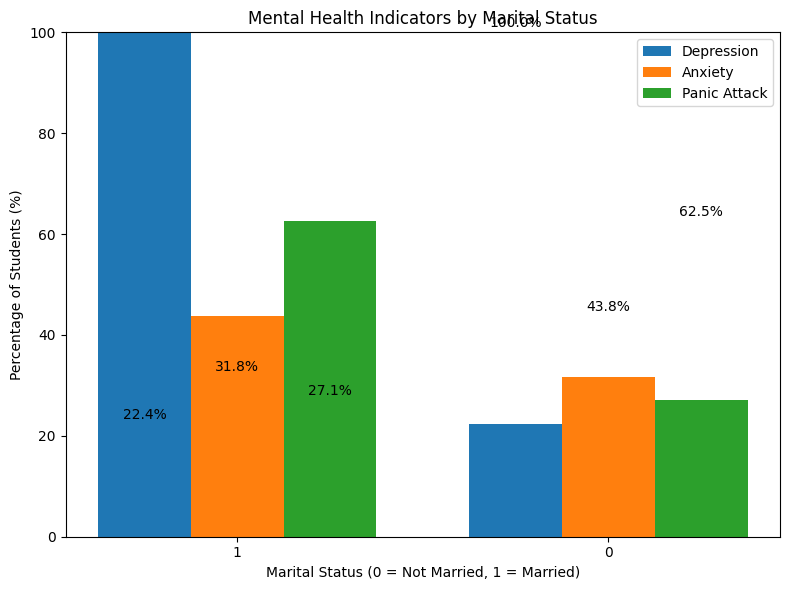

In [23]:
#Plot
x = np.arange(len(marital_mental.index))
width = 0.25

plt.figure(figsize=(8,6))

plt.bar(x - width, marital_mental['depression'], width, label='Depression')
plt.bar(x,         marital_mental['anxiety'], width, label='Anxiety')
plt.bar(x + width, marital_mental['panic_attack'], width, label='Panic Attack')

plt.xticks(x, marital_mental.index)
plt.xlabel('Marital Status (0 = Not Married, 1 = Married)')
plt.ylabel('Percentage of Students (%)')
plt.title('Mental Health Indicators by Marital Status')
plt.ylim(0,100)
plt.legend()

# Value labels
for i in range(len(x)):
    plt.text(x[i] - width, marital_mental['depression'][i] + 1,
             f"{marital_mental['depression'][i]:.1f}%", ha='center')
    plt.text(x[i], marital_mental['anxiety'][i] + 1,
             f"{marital_mental['anxiety'][i]:.1f}%", ha='center')
    plt.text(x[i] + width, marital_mental['panic_attack'][i] + 1,
             f"{marital_mental['panic_attack'][i]:.1f}%", ha='center')

plt.tight_layout()
plt.show()


>> married students shows higer level of depression, Unmarried students shows higher level of anxiety

### Graphical Annalysis 5: Mental Health by course of study

In [24]:
course_counts = df_eda['course'].value_counts()
course_counts


course
bcs                        18
engineering                17
bit                        10
koe                         6
biomedical science          4
benl                        3
pendidikan islam            3
psychology                  3
laws                        2
engine                      2
islamic education           2
kirkhs                      2
kop                         1
econs                       1
mhsc                        1
malcom                      1
biotechnology               1
human sciences              1
cts                         1
communication               1
diploma nursing             1
radiography                 1
fiqh fatwa                  1
diploma tesl                1
fiqh                        1
engin                       1
taasl                       1
it                          1
ala                         1
usuluddin                   1
law                         1
business administration     1
banking studies             1
mar

In [25]:
min_n = 3

top_courses = course_counts[course_counts >= min_n].index


In [26]:
#New grouped course column

df_course = df_eda.copy()

df_course['course_grouped'] = df_course['course'].where(
    df_course['course'].isin(top_courses),
    other='other'
)


In [27]:
df_course['course_grouped'].value_counts()


course_grouped
other                 37
bcs                   18
engineering           17
bit                   10
koe                    6
biomedical science     4
pendidikan islam       3
psychology             3
benl                   3
Name: count, dtype: int64

In [28]:
#Calculate mental health by course group
course_mental = (
    df_course
      .groupby('course_grouped')[['depression', 'anxiety', 'panic_attack']]
      .mean()
      .mul(100)
      .sort_values(by='depression', ascending=False)
)


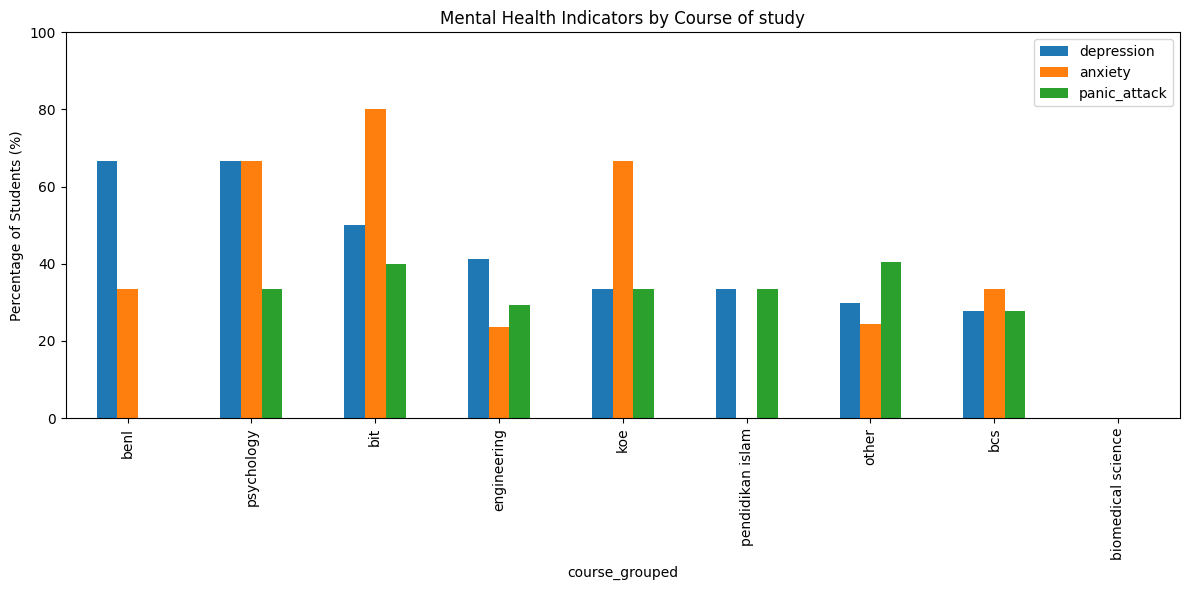

In [29]:
#Plot graph
course_mental.plot(kind='bar', figsize=(12,6))
plt.ylabel('Percentage of Students (%)')
plt.title('Mental Health Indicators by Course of study')
plt.ylim(0,100)
plt.tight_layout()
plt.show()


>>This chart shows how depression, anxiety, and panic attacks vary across different course groups.

# Term Project Milestone 2: Data Preparation

In [30]:
df.head()

,timestamp,gender,age,course,study_year,cgpa_raw,marital_status,depression,anxiety,panic_attack,sought_treatment,cgpa
0,8/7/2020 12:02,female,18.0,engineering,year_1,3.00 - 3.49,0,1,0,1,0,3.245
1,8/7/2020 12:04,male,21.0,islamic education,year_2,3.00 - 3.49,0,0,1,0,0,3.245
2,8/7/2020 12:05,male,19.0,bit,year_1,3.00 - 3.49,0,1,1,1,0,3.245
3,8/7/2020 12:06,female,22.0,laws,year_3,3.00 - 3.49,1,1,0,0,0,3.245
4,8/7/2020 12:13,male,23.0,mathemathics,year_4,3.00 - 3.49,0,0,0,0,0,3.245


### 1. Drop features that are not useful

In [31]:
df = df.drop(columns=['cgpa_raw'])  # We have taken CGPA midpoint already

In [32]:
df = df.drop(columns=['timestamp'])  #Timestamp only records data/survey submission time

### 2. Perform any data extraction/selection steps.

### Target 

>> Here we can choose depression as our target for prediction. Anxiety symptoms can fluctuate, and panic attacks are episodic and less predictable, which may create imbalance or instability in the analysis. Therefore, selecting depression as the target supports more accurate and interpretable predictions.

In [33]:
# Declaring the target 
y = df['depression']

In [34]:
X = df.drop(columns=['depression'])   #Remove from predictor features

### 3. Feature Transformation

In [35]:
df.columns

Index(['gender', 'age', 'course', 'study_year', 'marital_status', 'depression',
       'anxiety', 'panic_attack', 'sought_treatment', 'cgpa'],
      dtype='object')

In [36]:
df['cgpa'].value_counts()

cgpa
3.750    48
3.245    43
2.745     4
0.995     4
2.245     2
Name: count, dtype: int64

#### Missing values

In [37]:
#Missing values
df['cgpa'].isna().sum()

0

In [38]:
df['age'].isna().sum()

0

In [39]:
df['gender'].isna().sum()

0

In [40]:
df['anxiety'].isna().sum()

0

In [41]:
df['sought_treatment'].isna().sum()

0

In [42]:
#Feature  Transformation

#Convert study_year from text to numeric
df['study_year'] = df['study_year'].str.extract('(\d)').astype(int)    #ordinal encoding

In [43]:
df.head()

,gender,age,course,study_year,marital_status,depression,anxiety,panic_attack,sought_treatment,cgpa
0,female,18.0,engineering,1,0,1,0,1,0,3.245
1,male,21.0,islamic education,2,0,0,1,0,0,3.245
2,male,19.0,bit,1,0,1,1,1,0,3.245
3,female,22.0,laws,3,1,1,0,0,0,3.245
4,male,23.0,mathemathics,4,0,0,0,0,0,3.245


In [44]:
#Encode Gender for modeling
df['gender'] = df['gender'].map({'male': 0, 'female': 1})

In [45]:
#Identify major courses
df['course'].value_counts()

course
bcs                        18
engineering                17
bit                        10
koe                         6
biomedical science          4
benl                        3
pendidikan islam            3
psychology                  3
laws                        2
engine                      2
islamic education           2
kirkhs                      2
kop                         1
econs                       1
mhsc                        1
malcom                      1
biotechnology               1
human sciences              1
cts                         1
communication               1
diploma nursing             1
radiography                 1
fiqh fatwa                  1
diploma tesl                1
fiqh                        1
engin                       1
taasl                       1
it                          1
ala                         1
usuluddin                   1
law                         1
business administration     1
banking studies             1
mar

In [46]:
#Identify major courses (frequency >= 5)
major_courses = course_counts[course_counts >= 5].index

In [47]:
#Group major courses, keeping only commonly occurring courses
df['course_grouped'] = df['course'].apply(
    lambda x: x if x in major_courses else 'other'
)

In [48]:
df['course_grouped'].value_counts()

course_grouped
other          50
bcs            18
engineering    17
bit            10
koe             6
Name: count, dtype: int64

#### Create dummy variables

In [49]:
#Create Dummy variables (one-hot encoding)
df = pd.get_dummies(
    df,
    columns=['course_grouped'],
    drop_first=True,
    dtype=int   #binary
)

In [50]:
df.head()

,gender,age,course,study_year,marital_status,depression,anxiety,panic_attack,sought_treatment,cgpa,course_grouped_bit,course_grouped_engineering,course_grouped_koe,course_grouped_other
0,1,18.0,engineering,1,0,1,0,1,0,3.245,0,1,0,0
1,0,21.0,islamic education,2,0,0,1,0,0,3.245,0,0,0,1
2,0,19.0,bit,1,0,1,1,1,0,3.245,1,0,0,0
3,1,22.0,laws,3,1,1,0,0,0,3.245,0,0,0,1
4,0,23.0,mathemathics,4,0,0,0,0,0,3.245,0,0,0,1


In [51]:
#Drop course
df.drop(columns=['course'], inplace=True)

In [52]:
df.head()

,gender,age,study_year,marital_status,depression,anxiety,panic_attack,sought_treatment,cgpa,course_grouped_bit,course_grouped_engineering,course_grouped_koe,course_grouped_other
0,1,18.0,1,0,1,0,1,0,3.245,0,1,0,0
1,0,21.0,2,0,0,1,0,0,3.245,0,0,0,1
2,0,19.0,1,0,1,1,1,0,3.245,1,0,0,0
3,1,22.0,3,1,1,0,0,0,3.245,0,0,0,1
4,0,23.0,4,0,0,0,0,0,3.245,0,0,0,1


>> After encoding categorical variables, the dataset contains only numerical features suitable for modeling
>>
>> Features mill be added later if required as more comprehensive mental health or academic performance data becomes available
>>
>> The dataset was checked for missing values, and no significant missingness was observed.
>>
>> Continuous variables  may be standardized prior to modeling
>>
>> The target variable for this analysis is depression, which is binary, making the problem a binary classification task
>>
>> 

# 10.2 Term Project: Term Project Milestone 3: Model Building and Evaluation

### Problem Definition: The goal of this project is to build a classification model that predicts whether a student reports having depression based on demographic and academic characteristics.


In [53]:
correlation_matrix = df.corr()

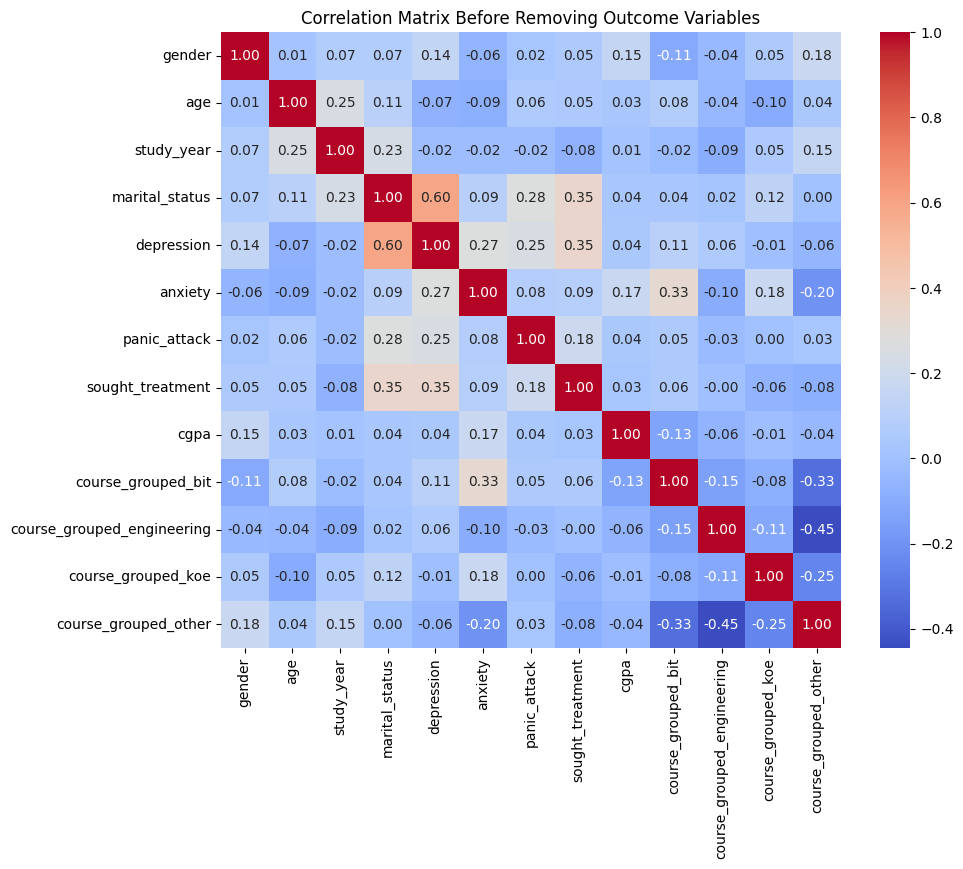

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, 
            annot=True, 
            cmap='coolwarm', 
            fmt='.2f')

plt.title('Correlation Matrix Before Removing Outcome Variables')
plt.show()

>> The correlation heatmap shows that depression has moderate positive correlations with anxiety and panic attack. Since anxiety and panic attack represent related mental health outcomes rather than independent background predictors, they need to be removed from the dataset.
>>
>> The goal of this study is to examine whether background characteristics such as CGPA range, gender, course of study, year of study, and marital status contribute to depression risk. Therefore, other outcome variables are excluded to ensure the model focuses only on predictive factors rather than overlapping mental health conditions.

In [55]:
# Remove Non-Target Outcome Variables
df_model = df.drop(columns=['anxiety', 'panic_attack', 'sought_treatment'])

In [56]:
df_model.columns

Index(['gender', 'age', 'study_year', 'marital_status', 'depression', 'cgpa',
       'course_grouped_bit', 'course_grouped_engineering',
       'course_grouped_koe', 'course_grouped_other'],
      dtype='object')

### Modeling

In [57]:
#Split X and y
target = "depression"
X = df_model.drop(columns=[target])
y = df_model[target]

In [58]:
#Split Train Test data


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=36,
    stratify=y  # keeps depression class ratio similar in train/test
)

#### Baseline model-Logistic Regression

In [59]:
#Baseline model

logreg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logreg_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])

Accuracy: 0.8571428571428571

Confusion Matrix Logistic Regression:
 [[14  0]
 [ 3  4]]

Classification Report Logistic Regression:
               precision    recall  f1-score   support

           0       0.82      1.00      0.90        14
           1       1.00      0.57      0.73         7

    accuracy                           0.86        21
   macro avg       0.91      0.79      0.82        21
weighted avg       0.88      0.86      0.84        21

ROC-AUC: 0.9744897959183674


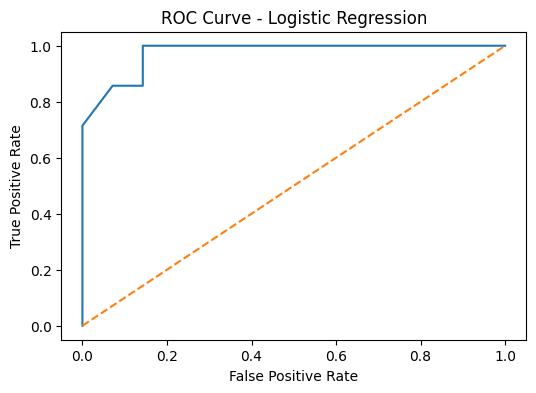

In [60]:
#Evaluate Model


# Predictions
y_pred = logreg_pipeline.predict(X_test)

# Probabilities for ROC-AUC (probability of class 1)
y_prob = logreg_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix Logistic Regression:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report Logistic Regression:\n", classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

>> Precision-Of all the cases the model predicted as positive, how many were actually positive? (TP / (TP + FP))
>>
>> Recall- Of all actual positive cases, how many did the model correctly identify?(TP / (TP + FN))
>>
>> The classification report provides more detailed metrics: precision shows how accurate the model’s positive predictions were, recall shows how many actual depressed students were correctly identified, and the F1-score balances both precision and recall. For depressed students, the recall was 0.57, meaning the model identified 57% of the actual depressed cases. The ROC-AUC score was 0.97, which indicates excellent overall ability of the model to distinguish between depressed and non-depressed students.

In [61]:
#check class balance
print("Class distribution (0/1):")
print(y.value_counts(normalize=True))

Class distribution (0/1):
depression
0    0.653465
1    0.346535
Name: proportion, dtype: float64


#### Compare with one more model-Random Forest

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Radom Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("\nRadom Forest Classification Report:\n", classification_report(y_test, rf_pred))


Radom Forest Accuracy: 0.9047619047619048

Radom Forest Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93        14
           1       0.86      0.86      0.86         7

    accuracy                           0.90        21
   macro avg       0.89      0.89      0.89        21
weighted avg       0.90      0.90      0.90        21



>> The test set contains 21 students because 20% of the total 101 samples were used for testing. Within these 21 students, 14 were not depressed and 7 were depressed, creating a moderate class imbalance. Since the test set is small, especially for the depressed class, evaluation metrics such as recall can change significantly with small prediction differences.

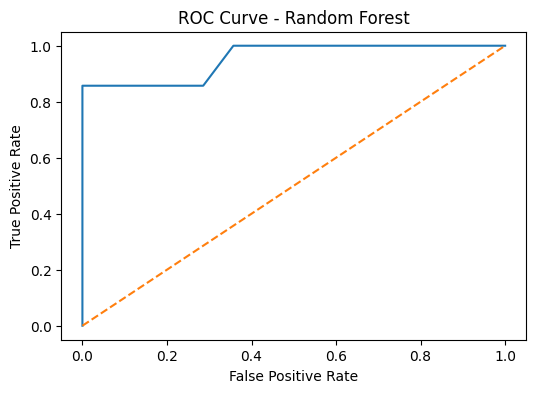

Random Forest ROC-AUC: 0.9540816326530611


In [74]:
# Compute ROC values
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, rf_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

# Plot
plt.figure(figsize=(6, 4))
plt.plot(fpr_rf, tpr_rf)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.show()

print("Random Forest ROC-AUC:", rf_auc)

>>The model achieved a precision of 0.86 and recall of 0.86, meaning it correctly identified most of the students who were actually depressed while also keeping false predictions low. The F1-score for depressed students was 0.86, indicating a good balance between precision and recall. The ROC-AUC score was approximately 0.95

#### Model Evaluation and comparison

>>Logistic Regression is very precise but misses many depressed students.

>>Random Forest performs more balanced and identifies more at-risk students.

>>In health-related prediction problems, recall is especially important because failing to identify an at-risk individual can have serious consequences. In this study, higher recall ensures that more students experiencing depression are correctly identified and can receive appropriate support.
>>
>>
>>Therefore, Random Forest is the better model for this problem.

In [76]:
#Actual vs Predicted DataFrame

rf_pred = rf_model.predict(X_test)


# Create comparison dataframe
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_pred
})

comparison_df

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,1,1
9,0,0


In [77]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   gender                      101 non-null    int64  
 1   age                         101 non-null    float64
 2   study_year                  101 non-null    int32  
 3   marital_status              101 non-null    int64  
 4   depression                  101 non-null    int64  
 5   cgpa                        101 non-null    float64
 6   course_grouped_bit          101 non-null    int32  
 7   course_grouped_engineering  101 non-null    int32  
 8   course_grouped_koe          101 non-null    int32  
 9   course_grouped_other        101 non-null    int32  
dtypes: float64(2), int32(5), int64(3)
memory usage: 6.0 KB


>> Since we have a small,  dataset, the model results may change if the data is split differently. Small datasets can sometimes cause the model to learn patterns that may not apply to a larger group of students. Although the results look good, they should be viewed carefully. Using a larger dataset in the future would make the results more reliable and accurate.

#### Limitations and Future Work
It is important to note that this dataset represents a sample dataset collected from a specific university in Malaysia. This project uses the dataset primarily for demonstration and learning purposes to illustrate data analysis and predictive modeling techniques. While the dataset provides useful insights into possible relationships between academic factors and student mental health, the results should not be considered fully representative of students in other universities or countries.
This study used a relatively small dataset of 101 students which is relatively small for machine learning analysis, so the results should be interpreted carefully. A larger dataset would improve the reliability of the analysis. Additional variables could be included to improve the analysis. Datasets such as the $ Healthy Minds Study$ include many more factors related to student mental health and could support more sophisticated machine learning models. Although these datasets require more time for data preparation, they could produce more accurate and useful results.This type of model could be used by universities to identify students who may be at risk of depression. Early identification would help institutions provide counseling, mental health resources, and academic support to improve student well-being.